# IMDB sentiment: bag-of-words baseline vs. bidirectional GRU + attention vs. transformer

This notebook follows up on `imdb_rnn_vs_attention.ipynb` and addresses Prof. Matthew McNeill's feedback on it.

| Feedback | What this notebook does |
|---|---|
| Simple baseline(s) to compare the RNN against | **Bag-of-words + logistic regression** (section 3) |
| Test a bidirectional RNN encoder | The GRU + attention model now has a **bidirectional** encoder. The one-direction version is retrained with the new settings as a control (sections 5, 7) |
| Get to transformers, start with the building blocks | A small **transformer encoder**, with attention, multi-head attention, positional encoding and the block written out by hand (section 6) |
| Smaller learning rate, train longer (25 epochs) | LR 1e-3 → **3e-4**, 5 → **25 epochs**, best epoch picked on the validation set |
| Half-precision training | Measured fp32 vs. fp16 vs. bf16 autocast on real batches (section 8) |
| DataLoader: `drop_last`, `num_workers`, `persistent_workers` | All used and timed (section 2) |
| No defensive empty-review guard: deal with data problems in the data | Checked up front that no review is empty. The guard is gone from `encode` (section 1) |
| Don't throw data away for efficiency | Truncation went from 256 to 1024 tokens (77% → 99.8% of tokens kept). Length bucketing keeps that affordable (section 2) |

## 0. Setup

Everything that can change between runs is set here, so all neural models share the same settings.

In [1]:
import math
import random
import re
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader

from imdb_data import PAD_ID, BucketBatchSampler, ReviewDataset, collate_batch

VOCAB_SIZE = 20_000      # 20k most common training words; the rest become <unk>
MAX_LEN = 1024           # truncate reviews to this many tokens (was 256)
BATCH_SIZE = 64
EPOCHS = 25              # was 5
LEARNING_RATE = 3e-4     # was 1e-3
SEED = 0

# recurrent models
EMBED_DIM = 128
HIDDEN_DIM = 128         # per direction
ATTN_DIM = 64
DROPOUT = 0.3

# transformer
MODEL_DIM = 128
NUM_HEADS = 4
FF_DIM = 256
NUM_LAYERS = 2
TRANSFORMER_DROPOUT = 0.1

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # not mps: see below
print("device:", device)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

device: cpu


**Why not the Mac GPU (`mps`)?** On a fixed-size benchmark batch, MPS looked attractive. The one-direction GRU ran at the same speed as the CPU (~300 ms per step), the BiGRU slightly faster, and the transformer about 6× faster (57 vs. 339 ms). Real training didn't hold up:

- **First full run:** the BiGRU's first epoch took 434 s on MPS, about twice the estimate. Its second epoch then crashed with `MPS backend out of memory`. PyTorch's own tensors were using only 0.7 GB, but the MPS driver's "other allocations" had grown to 19.5 GB.
- **Isolated test:** the bidirectional GRU's driver memory grew by about 1 GB every 60 training steps, even when the batch length never changed.
- **Transformer:** with real, varying batch lengths, it pushed the machine into swapping as well.

The CPU is just as fast for the GRUs and doesn't leak, so everything trains on the CPU. (On a machine with an NVIDIA GPU, `cuda` is used.)

## 1. Data, and checking it before modelling

Same data and split as before: 25k labelled training reviews, split 20k train / 5k validation with a fixed seed, plus the 25k test reviews.

In [2]:
DATA_DIR = Path("data")
IMDB_URL = "https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/{split}-00000-of-00001.parquet"

def load_split(split):
    path = DATA_DIR / f"imdb_{split}.parquet"
    if not path.exists():
        DATA_DIR.mkdir(exist_ok=True)
        urllib.request.urlretrieve(IMDB_URL.format(split=split), path)
    table = pd.read_parquet(path)
    return table["text"].tolist(), table["label"].tolist()

all_train_texts, all_train_labels = load_split("train")
test_texts, test_labels = load_split("test")

set_seed(SEED)
shuffled = list(range(len(all_train_texts)))
random.shuffle(shuffled)
train_indices, val_indices = shuffled[:20_000], shuffled[20_000:]
train_texts = [all_train_texts[i] for i in train_indices]
train_labels = [all_train_labels[i] for i in train_indices]
val_texts = [all_train_texts[i] for i in val_indices]
val_labels = [all_train_labels[i] for i in val_indices]
print(f"{len(train_texts)} train / {len(val_texts)} val / {len(test_texts)} test")

20000 train / 5000 val / 25000 test


The previous notebook had `return ids or [UNK_ID]  # guard against an empty review` in `encode`. Prof. McNeill's point is that data problems should be found and handled in the data, not patched inside the model code. A guard like that should be *demonstrably unnecessary*. So the check comes first.

In [3]:
def tokenize(text):
    text = text.lower().replace("<br />", " ")
    return re.findall(r"[a-z0-9']+", text)

token_counts = {name: np.array([len(tokenize(text)) for text in texts])
                for name, texts in [("train", train_texts), ("val", val_texts), ("test", test_texts)]}
for name, counts in token_counts.items():
    print(f"{name:>5}: shortest {counts.min():>3} tokens | median {np.median(counts):>4.0f} | "
          f"95th pct {np.percentile(counts, 95):>4.0f} | longest {counts.max()}")

assert all(counts.min() > 0 for counts in token_counts.values()), "an empty review exists: fix it in the data"
print("\nno empty reviews in any split, so encode() needs no guard")

counts = token_counts["train"]
for limit in (256, 512, 1024):
    kept = np.minimum(counts, limit).sum() / counts.sum()
    print(f"MAX_LEN={limit:>4}: {np.mean(counts > limit):6.1%} of reviews truncated, {kept:6.1%} of tokens kept")

train: shortest  10 tokens | median  176 | 95th pct  595 | longest 2473
  val: shortest  10 tokens | median  169 | 95th pct  609 | longest 1522
 test: shortest   6 tokens | median  172 | 95th pct  582 | longest 2246

no empty reviews in any split, so encode() needs no guard
MAX_LEN= 256:  29.6% of reviews truncated,  76.4% of tokens kept
MAX_LEN= 512:   7.7% of reviews truncated,  93.9% of tokens kept
MAX_LEN=1024:   0.1% of reviews truncated,  99.8% of tokens kept


The vocabulary is built from the **20k training reviews only**. The previous notebook built it from all 25k, which let the validation reviews leak into the vocabulary. The leak was small, but it's cleaner without it.

In [4]:
word_counts = Counter(word for text in train_texts for word in tokenize(text))
id_to_word = ["<pad>", "<unk>"] + [word for word, _ in word_counts.most_common(VOCAB_SIZE - 2)]
word_to_id = {word: index for index, word in enumerate(id_to_word)}
UNK_ID = 1
assert word_to_id["<pad>"] == PAD_ID

def encode(text):
    return [word_to_id.get(word, UNK_ID) for word in tokenize(text)][:MAX_LEN]

coverage = sum(c for w, c in word_counts.items() if w in word_to_id) / sum(word_counts.values())
print(f"vocabulary: {len(id_to_word):,} ids from {len(word_counts):,} distinct training words; "
      f"covers {coverage:.1%} of training tokens")
print("encoded:", encode("This movie was GREAT! Really, I loved it. Flibbertigibbet."))

vocabulary: 20,000 ids from 79,355 distinct training words; covers 97.2% of training tokens
encoded: [11, 17, 13, 78, 63, 10, 444, 9, 1]


## 2. Dataset and DataLoader

`ReviewDataset`, `collate_batch` and a new `BucketBatchSampler` live in [`imdb_data.py`](imdb_data.py). They're in a module because DataLoader workers on macOS start as fresh processes (`spawn`). Those processes can import a module, but they can't import classes defined in a notebook.

**Length bucketing.** With `MAX_LEN = 1024`, a random batch of 64 almost always contains one long review. The whole batch then gets padded to that length, and most of the compute goes to padding. The sampler shuffles, then sorts reviews within pools of 50 batches, so each batch holds reviews of similar length. The batch order is still shuffled every epoch.

**Prof. McNeill's DataLoader settings:**
- `drop_last=True` for training: no small, irregular final batch. Because batches come from the sampler, `drop_last` is an argument of the sampler here.
- `num_workers` / `persistent_workers=True`: timed below.

In [5]:
datasets = {name: ReviewDataset([encode(text) for text in texts], labels)
            for name, texts, labels in [("train", train_texts, train_labels),
                                        ("val", val_texts, val_labels),
                                        ("test", test_texts, test_labels)]}

def make_loader(split, num_workers=0):
    dataset = datasets[split]
    is_train = split == "train"
    sampler = BucketBatchSampler([len(ids) for ids in dataset.token_ids], BATCH_SIZE,
                                 shuffle=is_train, drop_last=is_train, seed=SEED)
    return DataLoader(dataset, batch_sampler=sampler, collate_fn=collate_batch,
                      num_workers=num_workers, persistent_workers=num_workers > 0)

token_ids, lengths, labels = next(iter(make_loader("train")))
print("one batch:", tuple(token_ids.shape), "| lengths", lengths.min().item(), "to", lengths.max().item())

def padding_fraction(loader):
    real = padded = 0
    for token_ids, lengths, _ in loader:
        real += lengths.sum().item()
        padded += token_ids.numel()
    return 1 - real / padded

random_loader = DataLoader(datasets["train"], batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch)
print(f"share of each batch that is padding: random batches {padding_fraction(random_loader):.0%}, "
      f"bucketed batches {padding_fraction(make_loader('train')):.0%}")

one batch: (64, 117) | lengths 113 to 117
share of each batch that is padding: random batches 73%, bucketed batches 4%


In [6]:
def time_two_epochs(num_workers):
    loader = make_loader("train", num_workers)
    start = time.time()
    for _ in range(2):
        for batch in loader:
            pass
    return time.time() - start

for workers in (0, 2, 4):
    print(f"num_workers={workers}: {time_two_epochs(workers):.2f}s to iterate 2 epochs of batches")

num_workers=0: 0.11s to iterate 2 epochs of batches


num_workers=2: 4.09s to iterate 2 epochs of batches


num_workers=4: 6.41s to iterate 2 epochs of batches


**Result:** `num_workers=0` is by far the fastest: 0.11 s, against 4.1 s with 2 workers and 6.4 s with 4.

- The reviews are already encoded as tensors in memory, so building a batch is only indexing plus padding.
- A worker process has to start up first (`spawn` re-imports everything). Then it sends every batch back to the main process, and that transfer costs far more than the work itself.
- `persistent_workers=True` removes the start-up cost after the first epoch, but not the transfer cost.

Workers pay off when `__getitem__` does real work, such as reading files from disk, decoding images or tokenizing on the fly. So `NUM_WORKERS = 0` here. If the data pipeline gets heavier, changing it is one line.

In [7]:
NUM_WORKERS = 0
loaders = {split: make_loader(split, NUM_WORKERS) for split in ("train", "val", "test")}
print({split: len(loader) for split, loader in loaders.items()}, "batches")

{'train': 312, 'val': 79, 'test': 391} batches


## 3. Baseline: bag-of-words + logistic regression

The simplest serious baseline. Each review becomes a vector with one entry per word in the vocabulary: 1 if the word appears, 0 if not. Word order is thrown away. Logistic regression then learns one weight per word, plus a bias. The prediction is `sigmoid(sum of the weights of the words present + bias)`.

The weights are learned by minimising the same binary cross-entropy loss the neural models use. It's a one-layer network with no hidden layer and no word order.

This baseline uses **every word of every review**: no 20k vocabulary cap and no truncation. `C` (inverse regularisation strength) is chosen on the validation set, just like the neural models' best epoch.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

vectorizer = CountVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None, binary=True)
bow_train = vectorizer.fit_transform(train_texts)
bow_val, bow_test = vectorizer.transform(val_texts), vectorizer.transform(test_texts)
print(f"bag-of-words matrix: {bow_train.shape[0]:,} reviews x {bow_train.shape[1]:,} words")

start = time.time()
best_c, best_val_acc, bow_model = None, 0.0, None
for c in (0.01, 0.03, 0.1, 0.3, 1.0):
    candidate = LogisticRegression(C=c, max_iter=2000).fit(bow_train, train_labels)
    val_acc = candidate.score(bow_val, val_labels)
    print(f"C={c:<5} val acc {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_c, best_val_acc, bow_model = c, val_acc, candidate
bow_seconds = time.time() - start

bow_test_probs = bow_model.predict_proba(bow_test)[:, 1]
bow_correct = (bow_test_probs > 0.5) == np.array(test_labels, dtype=bool)
bow_test_loss = -np.mean(np.where(test_labels, np.log(bow_test_probs), np.log(1 - bow_test_probs)))
print(f"\nbest C={best_c}: test accuracy {bow_correct.mean():.4f} (test loss {bow_test_loss:.3f}), "
      f"{bow_train.shape[1] + 1:,} parameters, {bow_seconds:.0f}s for all five fits")

bag-of-words matrix: 20,000 reviews x 79,355 words


C=0.01  val acc 0.8716


C=0.03  val acc 0.8800


C=0.1   val acc 0.8810


C=0.3   val acc 0.8786


C=1.0   val acc 0.8748

best C=0.1: test accuracy 0.8805 (test loss 0.294), 79,356 parameters, 4s for all five fits


Because the model is one weight per word, you can read it directly:

In [9]:
weights = bow_model.coef_[0]
words = vectorizer.get_feature_names_out()
order = np.argsort(weights)
print("most negative:", ", ".join(f"{words[i]} ({weights[i]:.2f})" for i in order[:12]))
print("most positive:", ", ".join(f"{words[i]} ({weights[i]:.2f})" for i in order[::-1][:12]))

most negative: worst (-1.46), waste (-1.24), awful (-1.14), poorly (-1.12), boring (-0.99), disappointment (-0.89), disappointing (-0.79), dull (-0.77), poor (-0.75), bad (-0.74), fails (-0.74), avoid (-0.73)
most positive: 7 (1.24), excellent (0.97), perfect (0.90), 8 (0.82), great (0.74), superb (0.72), amazing (0.71), rare (0.68), refreshing (0.67), wonderful (0.67), highly (0.66), favorite (0.65)


## 4. Shared training loop

One loop trains every neural model, so differences between them come from the architecture, not the training. The loop:
- uses Adam at `LEARNING_RATE` with gradient clipping at 1.0
- runs `EPOCHS` epochs
- keeps the weights from the epoch with the best validation accuracy

`precision` turns on autocast (`torch.float16` / `torch.bfloat16`) for the half-precision measurement in section 8.

In [10]:
loss_fn = nn.BCEWithLogitsLoss()

def run_batch(model, token_ids, lengths, labels, precision=None):
    token_ids, labels = token_ids.to(device), labels.to(device)
    with torch.autocast(device.type, dtype=precision, enabled=precision is not None):
        logits, _ = model(token_ids, lengths)
    logits = logits.float()
    return logits, labels, loss_fn(logits, labels)

def train_one_epoch(model, loader, optimizer, precision=None):
    model.train()
    total_loss, total_correct, total_count = 0.0, 0, 0
    for token_ids, lengths, labels in loader:
        logits, labels, loss = run_batch(model, token_ids, lengths, labels, precision)
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * len(labels)
        total_correct += ((logits > 0) == (labels == 1)).sum().item()
        total_count += len(labels)
    return total_loss / total_count, total_correct / total_count

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, total_correct, total_count = 0.0, 0, 0
    for token_ids, lengths, labels in loader:
        logits, labels, loss = run_batch(model, token_ids, lengths, labels)
        total_loss += loss.item() * len(labels)
        total_correct += ((logits > 0) == (labels == 1)).sum().item()
        total_count += len(labels)
    return total_loss / total_count, total_correct / total_count

def train_model(model, name):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best = {"val_acc": 0.0}
    start = time.time()
    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.time()
        train_loss, train_acc = train_one_epoch(model, loaders["train"], optimizer)
        val_loss, val_acc = evaluate(model, loaders["val"])
        for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):
            history[key].append(value)
        if val_acc > best["val_acc"]:
            best = {"val_acc": val_acc, "epoch": epoch,
                    "state": {k: v.detach().clone() for k, v in model.state_dict().items()}}
        print(f"[{name}] epoch {epoch:>2}: train loss {train_loss:.3f} acc {train_acc:.3f} | "
              f"val loss {val_loss:.3f} acc {val_acc:.3f} | {time.time() - epoch_start:.0f}s")
    model.load_state_dict(best["state"])
    history.update(best_epoch=best["epoch"], seconds=time.time() - start)
    print(f"[{name}] best epoch {best['epoch']} (val acc {best['val_acc']:.4f}), "
          f"total {history['seconds'] / 60:.1f} min")
    return history

count_parameters = lambda model: sum(p.numel() for p in model.parameters())

def make_padding_mask(token_ids, lengths):
    positions = torch.arange(token_ids.shape[1], device=token_ids.device)
    return positions.unsqueeze(0) < lengths.to(token_ids.device).unsqueeze(1)   # (batch, seq_len), True = real token

## 5. Bidirectional GRU + additive attention

The only change from the previous notebook's attention model is `bidirectional=True`. The GRU now reads every review twice: once left-to-right and once right-to-left. The hidden state at word *t* is the two directions' states concatenated:

- forward state at *t*: a summary of everything up to *t*
- backward state at *t*: a summary of everything after *t*

So each word's vector now has context from both sides. For example, "not" can be read in light of the word that follows it.

- **Keys/values:** the 256-dim concatenated states (128 per direction).
- **Query:** the forward GRU's final state (after reading the whole review) concatenated with the backward GRU's final state (after reading it backwards, so it ends at the first word).
- `AdditiveAttention` is unchanged from the previous notebook. It just receives 256-dim inputs.

With `bidirectional=False`, the same class gives back the previous notebook's model. It's retrained here as a control, so the comparison isolates bidirectionality from the new learning rate, epoch count and `MAX_LEN`.

In [11]:
class RecurrentEncoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, bidirectional):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True, bidirectional=bidirectional)
        self.output_dim = hidden_dim * (2 if bidirectional else 1)

    def forward(self, token_ids, lengths):
        embedded = self.embedding(token_ids)                                     # (batch, seq_len, embed_dim)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_states, last_hidden = self.rnn(packed)                            # last_hidden: (directions, batch, hidden_dim)
        encoder_states, _ = pad_packed_sequence(packed_states, batch_first=True,
                                                total_length=token_ids.shape[1])  # (batch, seq_len, output_dim)
        summary = torch.cat(list(last_hidden), dim=-1)                           # (batch, output_dim)
        return encoder_states, summary


class AdditiveAttention(nn.Module):
    def __init__(self, decoder_dim, encoder_dim, attn_dim):
        super().__init__()
        self.query_projection = nn.Linear(decoder_dim, attn_dim, bias=False)
        self.key_projection = nn.Linear(encoder_dim, attn_dim, bias=False)
        self.score_projection = nn.Linear(attn_dim, 1, bias=False)

    def forward(self, decoder_states, encoder_states, padding_mask):
        projected_query = self.query_projection(decoder_states)                  # (batch, attn_dim)
        projected_keys = self.key_projection(encoder_states)                     # (batch, seq_len, attn_dim)
        hidden = torch.tanh(projected_query.unsqueeze(1) + projected_keys)       # (batch, seq_len, attn_dim)
        scores = self.score_projection(hidden).squeeze(-1)                       # (batch, seq_len)
        scores = scores.masked_fill(~padding_mask, float("-inf"))
        attention_weights = torch.softmax(scores, dim=1)
        context_vector = (attention_weights.unsqueeze(-1) * encoder_states).sum(dim=1)
        return context_vector, attention_weights


class AttentionClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, attn_dim, dropout, bidirectional):
        super().__init__()
        self.encoder = RecurrentEncoder(vocab_size, embed_dim, hidden_dim, bidirectional)
        state_dim = self.encoder.output_dim
        self.attention = AdditiveAttention(state_dim, state_dim, attn_dim)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(state_dim, 1)

    def forward(self, token_ids, lengths):
        encoder_states, summary = self.encoder(token_ids, lengths)
        padding_mask = make_padding_mask(token_ids, lengths)
        context_vector, attention_weights = self.attention(summary, encoder_states, padding_mask)
        logits = self.classifier(self.dropout(context_vector)).squeeze(-1)       # (batch,)
        return logits, attention_weights

make_gru_attention = lambda bidirectional: AttentionClassifier(
    VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, ATTN_DIM, DROPOUT, bidirectional)

## 6. Transformer encoder, built from its pieces

The GRU builds each word's representation by walking the sequence one step at a time. A transformer replaces that walk with **self-attention**: every word looks at every other word directly, all in parallel.

The pieces, bottom-up:

1. **Scaled dot-product attention.** This is the same query/key/value idea as before, but the score is a dot product instead of the small `tanh` network of additive attention: `softmax(Q Kᵀ / √d) V`. In *self*-attention, every word is a query, so each word gets its own context vector, not just one for the whole review. Padding is masked out as before.
2. **Multi-head attention.** The 128 dims are split into 4 heads of 32. Each head has its own Q/K/V projections, so different heads can learn to look for different things, such as negations or adjectives. The heads' outputs are concatenated and mixed by one linear layer.
3. **Positional encoding.** Attention alone has no idea of word order: shuffle the words and the output is just shuffled the same way. Fixed sine/cosine waves of different frequencies are added to the embeddings, so position *t* has a unique signature.
4. **Encoder block** (pre-LayerNorm). It has two steps, each with a residual connection: `x + Attention(LayerNorm(x))`, then `x + FeedForward(LayerNorm(x))`. The feed-forward part is a 2-layer MLP applied to each word separately.
5. **Classifier.** Stack 2 blocks, average the final vectors over the real (non-padding) words, then apply a linear layer.

Sizes match the GRU's: a 128-dim model on top of the same 20k × 128 embedding.

In [12]:
def scaled_dot_product_attention(query, key, value, padding_mask):
    # query/key/value: (batch, heads, seq_len, head_dim); padding_mask: (batch, seq_len), True = real token
    scores = query @ key.transpose(-2, -1) / math.sqrt(query.shape[-1])          # (batch, heads, seq_len, seq_len)
    scores = scores.masked_fill(~padding_mask[:, None, None, :], float("-inf"))  # nobody attends to padding
    weights = torch.softmax(scores, dim=-1)
    return weights @ value, weights                                              # (batch, heads, seq_len, head_dim)


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, model_dim, num_heads):
        super().__init__()
        self.num_heads, self.head_dim = num_heads, model_dim // num_heads
        self.qkv_projection = nn.Linear(model_dim, 3 * model_dim)                # Q, K, V for all heads at once
        self.output_projection = nn.Linear(model_dim, model_dim)

    def forward(self, x, padding_mask):
        batch, seq_len, model_dim = x.shape
        qkv = self.qkv_projection(x).view(batch, seq_len, 3, self.num_heads, self.head_dim)
        query, key, value = qkv.permute(2, 0, 3, 1, 4)                            # each (batch, heads, seq_len, head_dim)
        attended, weights = scaled_dot_product_attention(query, key, value, padding_mask)
        attended = attended.transpose(1, 2).reshape(batch, seq_len, model_dim)    # concatenate the heads
        return self.output_projection(attended), weights


class TransformerBlock(nn.Module):
    def __init__(self, model_dim, num_heads, ff_dim, dropout):
        super().__init__()
        self.attention_norm = nn.LayerNorm(model_dim)
        self.attention = MultiHeadSelfAttention(model_dim, num_heads)
        self.feed_forward_norm = nn.LayerNorm(model_dim)
        self.feed_forward = nn.Sequential(nn.Linear(model_dim, ff_dim), nn.GELU(), nn.Linear(ff_dim, model_dim))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, padding_mask):
        attended, weights = self.attention(self.attention_norm(x), padding_mask)
        x = x + self.dropout(attended)
        x = x + self.dropout(self.feed_forward(self.feed_forward_norm(x)))
        return x, weights


def sinusoidal_positions(max_len, model_dim):
    positions = torch.arange(max_len).unsqueeze(1)                               # (max_len, 1)
    frequencies = torch.exp(torch.arange(0, model_dim, 2) * (-math.log(10_000.0) / model_dim))
    encoding = torch.zeros(max_len, model_dim)
    encoding[:, 0::2] = torch.sin(positions * frequencies)
    encoding[:, 1::2] = torch.cos(positions * frequencies)
    return encoding                                                              # (max_len, model_dim)


class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, model_dim, num_heads, ff_dim, num_layers, max_len, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, model_dim, padding_idx=PAD_ID)
        self.register_buffer("positions", sinusoidal_positions(max_len, model_dim))
        self.blocks = nn.ModuleList(TransformerBlock(model_dim, num_heads, ff_dim, dropout) for _ in range(num_layers))
        self.final_norm = nn.LayerNorm(model_dim)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(model_dim, 1)

    def forward(self, token_ids, lengths):
        padding_mask = make_padding_mask(token_ids, lengths)                     # (batch, seq_len)
        x = self.dropout(self.embedding(token_ids) + self.positions[:token_ids.shape[1]])
        for block in self.blocks:
            x, weights = block(x, padding_mask)
        x = self.final_norm(x)
        real = padding_mask.unsqueeze(-1).to(x.dtype)
        pooled = (x * real).sum(dim=1) / real.sum(dim=1)                         # mean over real words
        logits = self.classifier(self.dropout(pooled)).squeeze(-1)               # (batch,)
        return logits, weights                                                   # weights: last block, (batch, heads, seq, seq)

make_transformer = lambda: TransformerClassifier(
    VOCAB_SIZE, MODEL_DIM, NUM_HEADS, FF_DIM, NUM_LAYERS, MAX_LEN, TRANSFORMER_DROPOUT)

Sanity checks before training: shapes, attention ignores padding, and the hand-written attention matches PyTorch's built-in.

In [13]:
set_seed(SEED)
token_ids, lengths, labels = next(iter(loaders["val"]))
for name, model in [("GRU + attention", make_gru_attention(False)),
                    ("BiGRU + attention", make_gru_attention(True)),
                    ("transformer", make_transformer())]:
    model.eval()
    logits, weights = model(token_ids, lengths)
    print(f"{name:>18}: logits {tuple(logits.shape)}, attention {tuple(weights.shape)}, "
          f"{count_parameters(model):,} parameters")

# attention weights over padding are exactly zero, and each row sums to 1
shortest = lengths.argmin()
assert (weights[shortest, :, :, lengths[shortest]:] == 0).all()
assert torch.allclose(weights.sum(-1), torch.ones_like(weights.sum(-1)))

# padding tokens appended to a review do not change the transformer's prediction
one_review, one_length = token_ids[shortest:shortest + 1, :lengths[shortest]], lengths[shortest:shortest + 1]
padded_review = torch.cat([one_review, torch.full((1, 50), PAD_ID)], dim=1)
assert torch.allclose(model(one_review, one_length)[0], model(padded_review, one_length)[0], atol=1e-5)

# the hand-written attention matches torch.nn.functional.scaled_dot_product_attention
q, k, v = torch.randn(3, 2, 4, 10, 32).unbind(0)
mask = torch.arange(10).unsqueeze(0) < torch.tensor([[10], [6]])
ours, _ = scaled_dot_product_attention(q, k, v, mask)
theirs = nn.functional.scaled_dot_product_attention(q, k, v, attn_mask=mask[:, None, None, :])
assert torch.allclose(ours, theirs, atol=1e-5)
print("\nall checks passed")

   GRU + attention: logits (64,), attention (64, 44), 2,675,649 parameters
 BiGRU + attention: logits (64,), attention (64, 44), 2,791,233 parameters
       transformer: logits (64,), attention (64, 4, 44, 44), 2,825,345 parameters

all checks passed


## 7. Training (25 epochs each, LR 3e-4)

In [14]:
models, histories = {}, {}
set_seed(SEED)
models["GRU + attention"] = make_gru_attention(bidirectional=False)
histories["GRU + attention"] = train_model(models["GRU + attention"], "GRU + attention")

[GRU + attention] epoch  1: train loss 0.577 acc 0.693 | val loss 0.461 acc 0.779 | 194s


[GRU + attention] epoch  2: train loss 0.399 acc 0.822 | val loss 0.394 acc 0.826 | 197s


[GRU + attention] epoch  3: train loss 0.325 acc 0.864 | val loss 0.353 acc 0.850 | 198s


[GRU + attention] epoch  4: train loss 0.275 acc 0.890 | val loss 0.333 acc 0.858 | 201s


[GRU + attention] epoch  5: train loss 0.240 acc 0.906 | val loss 0.308 acc 0.870 | 190s


[GRU + attention] epoch  6: train loss 0.199 acc 0.923 | val loss 0.306 acc 0.874 | 208s


... (15 outputs left out)

[GRU + attention] epoch 22: train loss 0.010 acc 0.997 | val loss 0.769 acc 0.865 | 309s


[GRU + attention] epoch 23: train loss 0.005 acc 0.999 | val loss 0.819 acc 0.870 | 248s


[GRU + attention] epoch 24: train loss 0.003 acc 0.999 | val loss 0.835 acc 0.864 | 275s


[GRU + attention] epoch 25: train loss 0.006 acc 0.998 | val loss 0.994 acc 0.864 | 283s
[GRU + attention] best epoch 9 (val acc 0.8752), total 145.7 min


In [15]:
set_seed(SEED)
models["BiGRU + attention"] = make_gru_attention(bidirectional=True)
histories["BiGRU + attention"] = train_model(models["BiGRU + attention"], "BiGRU + attention")

[BiGRU + attention] epoch  1: train loss 0.560 acc 0.704 | val loss 0.444 acc 0.790 | 550s


[BiGRU + attention] epoch  2: train loss 0.382 acc 0.831 | val loss 0.366 acc 0.837 | 538s


[BiGRU + attention] epoch  3: train loss 0.304 acc 0.872 | val loss 0.344 acc 0.848 | 545s


[BiGRU + attention] epoch  4: train loss 0.257 acc 0.896 | val loss 0.314 acc 0.861 | 1440s


[BiGRU + attention] epoch  5: train loss 0.212 acc 0.915 | val loss 0.305 acc 0.866 | 372s


[BiGRU + attention] epoch  6: train loss 0.177 acc 0.933 | val loss 0.332 acc 0.861 | 464s


... (15 outputs left out)

[BiGRU + attention] epoch 22: train loss 0.006 acc 0.998 | val loss 0.995 acc 0.869 | 475s


[BiGRU + attention] epoch 23: train loss 0.012 acc 0.997 | val loss 1.066 acc 0.872 | 476s


[BiGRU + attention] epoch 24: train loss 0.008 acc 0.997 | val loss 0.966 acc 0.871 | 496s


[BiGRU + attention] epoch 25: train loss 0.006 acc 0.998 | val loss 0.976 acc 0.873 | 500s
[BiGRU + attention] best epoch 25 (val acc 0.8726), total 252.0 min


In [16]:
set_seed(SEED)
models["transformer"] = make_transformer()
histories["transformer"] = train_model(models["transformer"], "transformer")

[transformer] epoch  1: train loss 0.603 acc 0.653 | val loss 0.499 acc 0.747 | 121s


[transformer] epoch  2: train loss 0.442 acc 0.793 | val loss 0.435 acc 0.803 | 125s


[transformer] epoch  3: train loss 0.382 acc 0.830 | val loss 0.365 acc 0.838 | 127s


[transformer] epoch  4: train loss 0.332 acc 0.856 | val loss 0.367 acc 0.841 | 123s


[transformer] epoch  5: train loss 0.307 acc 0.870 | val loss 0.360 acc 0.851 | 123s


[transformer] epoch  6: train loss 0.287 acc 0.882 | val loss 0.340 acc 0.854 | 124s


... (15 outputs left out)

[transformer] epoch 22: train loss 0.089 acc 0.967 | val loss 0.530 acc 0.872 | 101s


[transformer] epoch 23: train loss 0.081 acc 0.970 | val loss 0.512 acc 0.869 | 101s


[transformer] epoch 24: train loss 0.064 acc 0.976 | val loss 0.540 acc 0.873 | 102s


[transformer] epoch 25: train loss 0.062 acc 0.978 | val loss 0.584 acc 0.869 | 102s
[transformer] best epoch 24 (val acc 0.8734), total 65.2 min


## 8. Half precision

In half precision, most of the math runs in 16-bit floats instead of 32-bit. `torch.autocast` picks which operations are safe to run in 16 bits. On GPUs with tensor cores (NVIDIA), this is often close to 2× faster and halves activation memory. Below, each architecture runs the same 20 training batches in each precision, with timing done after a warm-up.

In [17]:
timing_batches = [batch for batch, _ in zip(loaders["train"], range(22))]

def seconds_per_batch(make_model, precision):
    set_seed(SEED)
    model = make_model().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    model.train()
    for index, (token_ids, lengths, labels) in enumerate(timing_batches):
        if index == 2:                                   # first two batches are warm-up
            start = time.time()
        _, _, loss = run_batch(model, token_ids, lengths, labels, precision)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return (time.time() - start) / (len(timing_batches) - 2)

print(f"{'model':>18} | {'float32':>8} | {'float16':>8} | {'bfloat16':>8}   (ms per training batch on {device})")
for name, make_model in [("BiGRU + attention", lambda: make_gru_attention(True)), ("transformer", make_transformer)]:
    times = [seconds_per_batch(make_model, precision) * 1000 for precision in (None, torch.float16, torch.bfloat16)]
    print(f"{name:>18} | " + " | ".join(f"{t:>8.0f}" for t in times))

             model |  float32 |  float16 | bfloat16   (ms per training batch on cpu)


 BiGRU + attention |     1343 |     2463 |     2829


       transformer |      370 |     4022 |     4049


**Result: half precision is slower on this machine, so all the training above is in fp32.**

| | fp32 | fp16 | bf16 |
|---|---|---|---|
| BiGRU, CPU (ms per batch) | 1343 | 2463 | 2829 |
| Transformer, CPU (ms per batch) | 370 | 4022 | 4049 |

Autocast makes the BiGRU about 2× slower and the transformer about 11× slower. The earlier benchmarks on the Mac GPU (MPS) showed the same pattern: the BiGRU went from 513 to ~870 ms, and the transformer from 57 to 62 ms.

Half precision only speeds things up on hardware with fast 16-bit math units, such as NVIDIA tensor cores. The M2's CPU has no fast fp16 matrix path. Autocast adds conversions around every operation, and there's no faster kernel to pay for them.

On a CUDA GPU this is worth repeating. That's where mixed precision usually gives a 1.5–2× speed-up and halves activation memory (fp16 with a `GradScaler`, or bf16). In Lightning it is one argument: `Trainer(precision="16-mixed")`.

## 9. Results

In [18]:
@torch.no_grad()
def test_predictions(model):
    # per-review correctness, put back in the original test order (the test loader sorts by length)
    model.eval()
    order = [index for batch in loaders["test"].batch_sampler for index in batch]
    correct = []
    for token_ids, lengths, labels in loaders["test"]:
        logits, labels, _ = run_batch(model, token_ids, lengths, labels)
        correct.append(((logits > 0) == (labels == 1)).cpu())
    correct = torch.cat(correct).numpy()
    aligned = np.empty_like(correct)
    aligned[order] = correct
    return aligned

test_correct = {"bag-of-words + LR": bow_correct}
rows = [("bag-of-words + LR", bow_train.shape[1] + 1, bow_correct.mean(), bow_test_loss, "-", bow_seconds / 60)]
for name, model in models.items():
    test_loss, test_acc = evaluate(model, loaders["test"])
    test_correct[name] = test_predictions(model)
    assert abs(test_correct[name].mean() - test_acc) < 1e-9
    rows.append((name, count_parameters(model), test_acc, test_loss,
                 histories[name]["best_epoch"], histories[name]["seconds"] / 60))

summary = pd.DataFrame(rows, columns=["model", "parameters", "test accuracy", "test loss", "best epoch", "train minutes"])
summary.style.format({"parameters": "{:,}", "test accuracy": "{:.4f}", "test loss": "{:.3f}",
                      "train minutes": "{:.1f}"}).hide(axis="index")

model,parameters,test accuracy,test loss,best epoch,train minutes
bag-of-words + LR,"79,356",0.8805,0.294,-,0.1
GRU + attention,"2,675,649",0.8718,0.360,9,145.7
BiGRU + attention,"2,791,233",0.8662,1.042,25,252.0
transformer,"2,825,345",0.8571,0.631,24,65.2


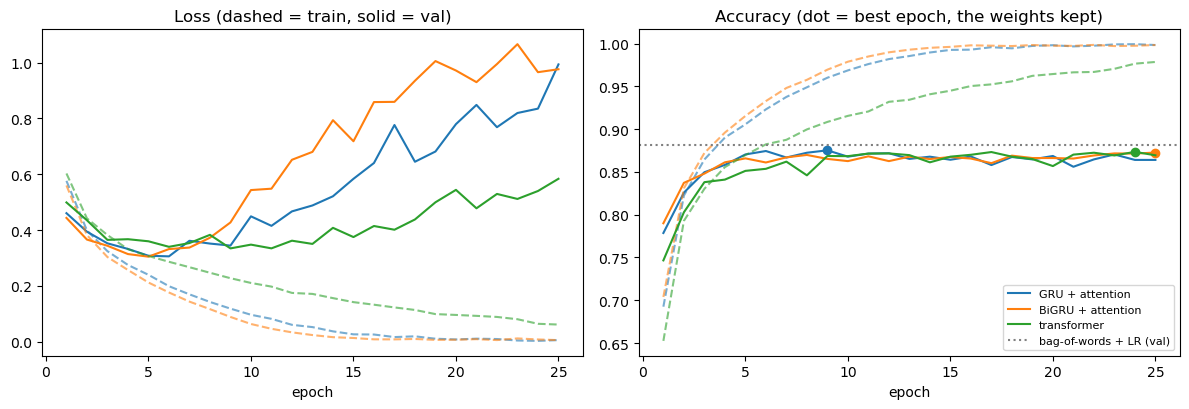

In [19]:
epochs = range(1, EPOCHS + 1)
colors = {"GRU + attention": "tab:blue", "BiGRU + attention": "tab:orange", "transformer": "tab:green"}
figure, (loss_axis, acc_axis) = plt.subplots(1, 2, figsize=(12, 4.2))
for name, history in histories.items():
    loss_axis.plot(epochs, history["train_loss"], "--", color=colors[name], alpha=0.6)
    loss_axis.plot(epochs, history["val_loss"], "-", color=colors[name], label=name)
    acc_axis.plot(epochs, history["train_acc"], "--", color=colors[name], alpha=0.6)
    acc_axis.plot(epochs, history["val_acc"], "-", color=colors[name], label=name)
    acc_axis.plot(history["best_epoch"], history["val_acc"][history["best_epoch"] - 1], "o", color=colors[name])
acc_axis.axhline(best_val_acc, color="gray", linestyle=":", label="bag-of-words + LR (val)")
loss_axis.set(title="Loss (dashed = train, solid = val)", xlabel="epoch")
acc_axis.set(title="Accuracy (dot = best epoch, the weights kept)", xlabel="epoch")
acc_axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

Accuracy by review length. Lengths are the full token counts, before truncation.

In [20]:
test_token_counts = token_counts["test"]
buckets = [(0, 100), (100, 200), (200, 400), (400, MAX_LEN), (MAX_LEN, 10**6)]
table = {}
for low, high in buckets:
    in_bucket = (test_token_counts > low) & (test_token_counts <= high)
    label = f"{low + 1}-{high}" if high < 10**6 else f">{low}"
    table[label] = {"reviews": int(in_bucket.sum()),
                    **{name: correct[in_bucket].mean() for name, correct in test_correct.items()}}
pd.DataFrame(table).T.astype({"reviews": int}).style.format({name: "{:.4f}" for name in test_correct}).format({"reviews": "{:,}"})

,reviews,bag-of-words + LR,GRU + attention,BiGRU + attention,transformer
1-100,"3,163",0.885868,0.872273,0.877332,0.860575
101-200,"11,758",0.881017,0.872767,0.866899,0.858564
201-400,"6,971",0.877206,0.872759,0.869603,0.859848
401-1024,"3,096",0.880814,0.865956,0.844961,0.842377
>1024,12,0.750000,0.833333,0.750000,0.666667


### Where the BiGRU attends

Same visualisation as before. Darker means more attention weight.

In [21]:
from html import escape
from IPython.display import HTML, display

@torch.no_grad()
def show_attention(model, text, true_label):
    model.eval()
    ids = encode(text)
    logits, weights = model(torch.tensor([ids], device=device), torch.tensor([len(ids)]))
    weights = weights[0].cpu().numpy()
    probability = torch.sigmoid(logits).item()
    words = [id_to_word[i] for i in ids]
    strength = weights / weights.max()
    spans = "".join(f'<span style="background: rgba(255,140,0,{s:.2f}); padding: 1px 2px">{escape(w)}</span> '
                    for w, s in zip(words, strength))
    verdict = "positive" if probability > 0.5 else "negative"
    top_words = [words[i] for i in np.argsort(weights)[::-1][:8]]
    display(HTML(f"<p><b>true: {'positive' if true_label else 'negative'} | predicted: {verdict} "
                 f"({probability:.2f})</b><br>top words: {', '.join(top_words)}</p>"
                 f"<p style='line-height: 1.8'>{spans}</p><hr>"))

random.seed(1)
for index in random.sample(range(len(test_texts)), 3):
    show_attention(models["BiGRU + attention"], test_texts[index], test_labels[index])
show_attention(models["BiGRU + attention"],
               "The acting was wooden and the plot made no sense, but the soundtrack was "
               "absolutely wonderful. Still, I would not watch it again.", 0)

## 10. What the results say

| model | test accuracy | parameters | training time |
|---|---|---|---|
| bag-of-words + logistic regression | **88.05%** | 79k | 4 s (all five `C` values) |
| GRU + attention | 87.18% | 2.68M | 2.4 h |
| BiGRU + attention | 86.62% | 2.79M | 4.2 h |
| transformer | 85.71% | 2.83M | 1.1 h |

For reference, the previous notebook got 85.7% for the GRU and 86.9% for GRU + attention.

**1. The simplest model wins.** Bag-of-words + logistic regression is the most accurate model:
- It has 35× fewer parameters and fits in seconds instead of hours.
- It wins every length bucket except >1024 tokens, which holds only 12 reviews.
- Its largest weights are the obvious words: *worst, waste, awful* and *excellent, perfect, superb*. Ratings like "7" and "8" that reviewers type into their text also rank high.

For IMDB, *which* words appear decides most reviews. Word order matters for a minority, such as negation ("not good") and contrast ("…but"). From 20k reviews, the sequence models don't learn enough about order to make up for what they lose elsewhere. Word-count baselines are known to be strong on this dataset. Neural models usually pull ahead only when they start from pretrained word embeddings or a pretrained language model.

**2. All three neural models overfit early. The 25 epochs mainly show that.**
- Validation loss bottoms out early: GRU + attention at epoch 6 (0.306), BiGRU at epoch 5 (0.305), transformer at epochs 9–11 (0.335).
- After that, validation loss climbs while training accuracy rises to 97–99.8%.
- Validation accuracy plateaus around 86.5–87.5% from about epoch 5 onward.

The smaller learning rate gives smoother curves. GRU + attention went from 86.9% to 87.2%, but that isn't a pure learning-rate effect, because `MAX_LEN` and the vocabulary also changed. Training past epoch ~10 adds nothing. Each model has 2.7M+ parameters, 2.56M of them in the embedding table, against 20k training reviews, so they memorise.

**3. Bidirectional did not help here.** The BiGRU scored 86.6% vs. 87.2% (best validation accuracy 0.8726 vs. 0.8752). With one seed per model, a 0.5-point gap is within run-to-run noise. Still, the extra context from both sides bought nothing measurable, and it doubled the training time. It was weaker on long reviews: 84.5% vs. 86.6% on 401–1024 tokens.

Its attention maps are also harder to read. In the second example above, most of the weight sits on "and". Each bidirectional state mixes in context from both sides, so the state at "and" can stand for its neighbours. A weight on a state is no longer a weight on a single word.

**4. The transformer, trained from scratch, is the weakest of the four, but it's the fastest neural model per epoch.** It took about 2 min per epoch on the CPU, vs. 3–4 min for the GRU and 8–9 min for the BiGRU, because it processes all positions in parallel instead of one word at a time. Unlike the GRUs, it has no built-in sense of word order, only the added positional encoding. Transformers are known to need more data, or pretraining, to beat recurrent models. With 20k reviews, it isn't there.

**5. A flaw in this run: how the best epoch was chosen.** `train_model` keeps the epoch with the highest validation *accuracy*.
- Validation accuracy is flat after epoch ~5, so the pick is mostly noise. For the BiGRU and the transformer, it landed on very late, overfit epochs (25 and 24).
- Those models are badly overconfident. Their test losses are 1.04 and 0.63, against 0.29 for the baseline, even though the accuracies are close.
- Choosing by validation *loss* would have picked epochs 5–11: similar accuracy, much better-calibrated probabilities, and about half the training time with early stopping.

**Next steps**
- Select checkpoints on validation loss, with early stopping.
- Regularise the neural models where they overfit: weight decay, dropout on the embeddings, or pretrained word embeddings (e.g. GloVe) instead of learning 2.56M embedding weights from 20k reviews.
- Give the baseline word pairs (bigrams), so it can represent "not good".
- Run several seeds per model. Single-seed differences of under a point between the neural models can't be ranked reliably.
- Move the training loop to Lightning. Early stopping, checkpointing and mixed precision are built-in callbacks and flags there.